# 4. Price Level Histories

This notebook investigates historical fluctuations in the levels of aggregate price indices.

The `xlrd` package is used by `pandas` to perform operations on Excel files.

In [1]:
!pip install xlrd

/bin/bash: /Users/jacaseyclyde/projects/quantecon/quantecon-notebooks/.venv/bin/pip: /Users/jacaseyclyde/projects/quantecon/.venv/bin/python: bad interpreter: No such file or directory


In [2]:
from importlib.metadata import version
from packaging.version import Version

if Version(version("pandas")) < Version('2.1.4'):
    !pip install "pandas>=2.1.4"

We first import packages.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

The price level rate of growth is called inflation in the popular lexicon. The price level itself is measured in units of domestic currency per units of a representative bundle of consumer goods. For example, in the US, the price level at $t$ (which is typically take in months or years) is measures in dollars per consumption bundle unit.

In many western countries price levels fluctuated from year to year, but didn't have much of a trend until the early 20th century. Prior to this time, they typically ended the century near where they started. This changed over the 20th century, however, as we shall see in this notebook. According to QuantEcon, a widely held hypothesis is that this was a result of countries abandoning the gold standard around this time.

## 4.1. Four Centuries of Price Levels

We start by plotting price levels for four "hard currency" countires -- France, Spain (Castile), the United Kingdom, and the United States -- from 1600 to 1914. This data originally appeared on page 35 of [Sargent and Velde, 2002]. The phrase "hard currency" means that the countries used a commodity-money standard: money was issued as hard coins of gold and silver, whose values were determined by their weights.

> Note: under a gold or silver standard, some money also consisted of "warehouse certificates" (e.g., bank notes issued by the government or private banks) which represented paper claims on gold and/or silver coins.

Let's import data from a spreadsheet on the QuantEcon GitHub.

In [ ]:
# Import data and clean up the index
data_url = "https://github.com/QuantEcon/data-lectures/raw/main/lectures/longprices.xls"
df_fig5 = pd.read_excel(
    data_url, sheet_name="all", header=2, index_col=0
).iloc[1:]
df_fig5.index = df_fig5.index.astype(int)

Below we show the price levels from 1600-1914. These countries were on a gold or silver standard for a majority of this time.

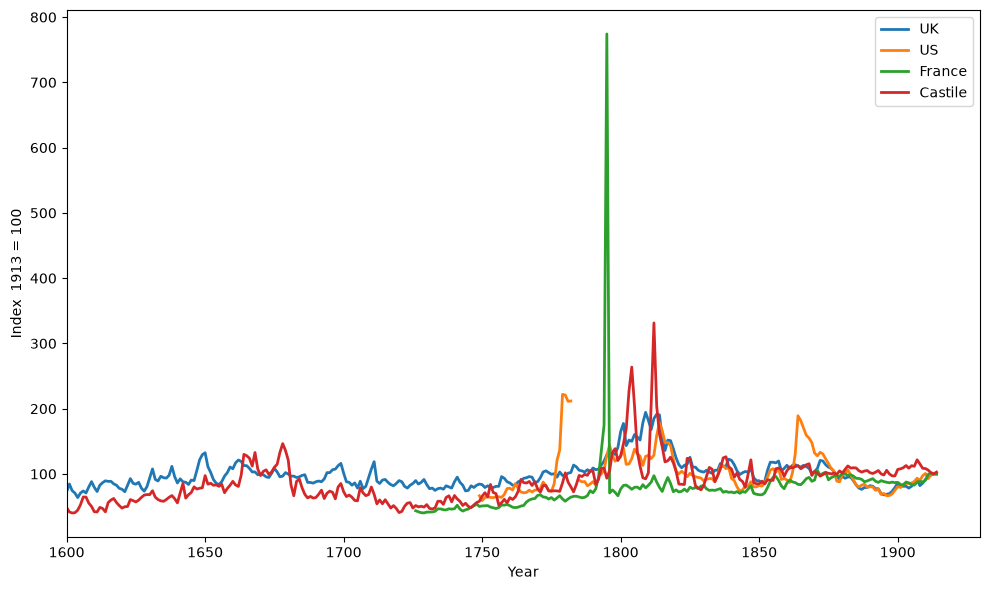

In [ ]:
df_fig5_befe1914 = df_fig5[df_fig5.index <= 1914]

# Create plot
cols = ["UK", "US", "France", "Castile"]

fig, ax = plt.subplots(figsize=(10, 6))

for col in cols:
    ax.plot(df_fig5_befe1914.index, df_fig5_befe1914[col], label=col, lw=2)

ax.legend()
ax.set_ylabel("Index  1913 = 100")
ax.set_xlabel("Year")
ax.set_xlim(xmin=1600)
plt.tight_layout()
plt.show()

Looking at the plot, we can see several massive spikes in price levels in each country. During these times, the gold and silver standards were abandoned, usually due to needing to print money during war. For example, from 1776 - 1790 we can see a spike in the US due to the American Revolution, and again from 1861-1865 during the US Civil War. In Fracne we can see a large spike from 1791-1797, during the French Revolution.

The other striking feature is that, over the first three centuries, the overall price level remained relatively constant. 

In the early 20th century, two other features of this data attracted the attention of Irving Fisher of Yale University and John Maynard Keynes of Cambridge University.
  * Despite being anchored to the same average level over long time spans, there were considerable year-to-year variations in price levels
  * While using valuable gold and silver as coins succeeded in anchoring the price level by limiting the supply of money, it cost real resources.
  * Countries paid a high “opportunity cost” for using gold and silver coins as money – that gold and silver could instead have been made into valuable jewelry and other durable goods.

Keynes and Fisher proposed what they claimed would be a more efficient way to achieve a price level that would be at least as firmly anchored as achieved under a gold or silver standard, and would also exhibit less year-to-year short-term fluctuations.

They said that central banks could achieve price level stability by
  1. issuing limited supplies of paper currency
  2. refusing to print money to finance government expenditures

This logic prompted John Maynard Keynes to call a commodity standard a “barbarous relic.”

A paper currency or “fiat money” system disposes of all reserves behind a currency.

But adhering to a gold or silver standard had provided an automatic mechanism for limiting the supply of money, thereby anchoring the price level.

To anchor the price level, a pure paper or fiat money system replaces that automatic mechanism with a central bank with the authority and determination to limit the supply of money (and to deter counterfeiters!)

Now let’s see what happened to the price level in the four countries after 1914, when one after another of them left the gold/silver standard by showing the complete graph that originally appeared on page 35 of [Sargent and Velde, 2002].

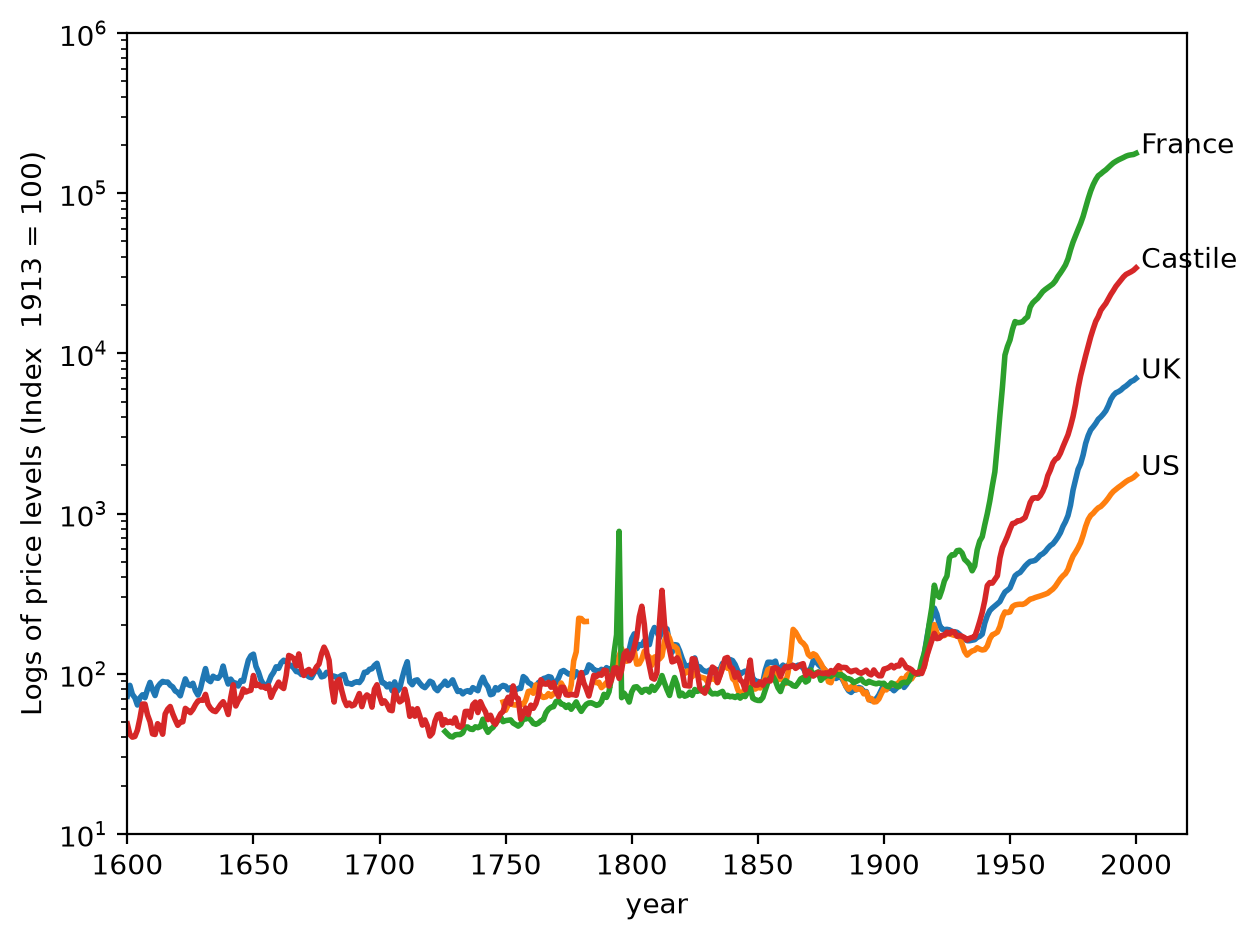

In [ ]:
fig, ax = plt.subplots(dpi=200)

for col in cols:
    ax.plot(df_fig5.index, df_fig5[col], lw=2)
    ax.text(x=df_fig5.index[-1] + 2, y=df_fig5[col].iloc[-1], s=col)

ax.set_yscale("log")
ax.set_ylabel("Logs of price levels (Index  1913 = 100)")
ax.set_ylim([10, 1e6])
ax.set_xlabel("year")
ax.set_xlim(xmin=1600)
plt.tight_layout()
plt.show()

Fig. 4.2 shows the logarithm of price levels over four “hard currency” countries from 1600 to 2000.

> **Note:** Although we didn’t have to use logarithms in our earlier graphs that had stopped in 1914, we now choose to use logarithms because we want to fit observations after 1914 in the same graph as the earlier observations.

After the outbreak of the Great War in 1914, the four countries left the gold standard and in so doing acquired the ability to print money to finance government expenditures. As we can see, central banks did not anchor the price level under a fiat system as well as the gold and silver standards did. In fact, the breadth and length of the inflationary period under a paper money fiat system is historically unprecedented.

It turns out Keynes and Fisher were not the first to conceive of fiat money systems, but economists in centuries prior were hesitant to trust central banks and and governments to properly manage the system. Given the high inflation since abandoning the gold and silver standards, it's hard to argue such concerns were unfounded.

## 4.2. Four Big Inflations

In the wake of WWI, which ended November 1918, monetary and fiscal authorities struggled to achieve price level stability without being on a gold or silver standard.

Here we examine four plots from “The Ends of Four Big Inflations,” Chapter 3 of [Sargent, 2013].

The plots depict logarithms of price levels during the early post World War I years for four countries:
  * Retail prices Austria, 1921-1924 (page 42)
  * Wholesale prices Hungary, 1921-1924 (page 43)
  * Wholesale prices, Poland, 1921-1924 (page 44)
  * Wholesale prices, Germany, 1919-1924 (page 45)

We have added logarithms of the exchange rates vis-à-vis the US dollar to each of the four plots from chapter 3 of [Sargent, 2013].

Data underlying these plots appear in tables in an appendix to chapter 3 of [Sargent, 2013]. QuantEcon has transcribed all of these data into a spreadsheet `chapter_3.xlsx` that we read into `pandas`.

In the code cell below we clean the data and build a `pandas.dataframe`.

In [ ]:
def process_entry(entry):
    "Clean each entry of a dataframe."

    if type(entry) == str:
        # Remove leading and trailing whitespace
        entry = entry.strip()
        # Remove comma
        entry = entry.replace(",", "")

        # Remove HTML markers
        item_to_remove = ["<s>a</s>", "<s>c</s>", "<s>d</s>", "<s>e</s>"]

        # <s>b</s> represents a billion
        if "<s>b</s>" in entry:
            entry = entry.replace("<s>b</s>", "")
            entry = float(entry) * 1e9
        else:
            for item in item_to_remove:
                if item in entry:
                    entry = entry.replace(item, "")
    return entry


def process_df(df):
    "Clean and reorganize the entire dataframe."

    # Remove HTML markers from column names
    for item in ["<s>a</s>", "<s>c</s>", "<s>d</s>", "<s>e</s>"]:
        df.columns = df.columns.str.replace(item, "")

    # Convert years to int
    df["Year"] = df["Year"].apply(lambda x: int(x))

    # Set index to datetime with year and month
    df = df.set_index(
        pd.to_datetime(
            (df["Year"].astype(str) + df["Month"].astype(str)), format="%Y%B"
        )
    )
    df = df.drop(["Year", "Month"], axis=1)

    # Handle duplicates by keeping the first
    df = df[~df.index.duplicated(keep="first")]

    # Convert attribute values to numeric
    df = df.map(lambda x: float(x) if x != "\u2014" else np.nan)

    # Finally, we only focus on data between 1919 and 1925
    mask = (df.index >= "1919-01-01") & (df.index < "1925-01-01")
    df = df.loc[mask]

    return df

Next we define plotting functions.

In [ ]:
def pe_plot(p_seq, e_seq, index, labs, ax):
    "Generate plots for price and exchange rates."

    p_lab, e_lab = labs

    # Plot price and exchange rates
    ax.plot(index, p_seq, label=p_lab, color="tab:blue", lw=2)

    # Add a new axis
    ax1 = ax.twinx()
    ax1.plot([None], [None], label=p_lab, color="tab:blue", lw=2)
    ax1.plot(index, e_seq, label=e_lab, color="tab:orange", lw=2)

    # Set log axes
    ax.set_yscale("log")
    ax1.set_yscale("log")

    # Define the axis label format
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    for label in ax.get_xticklabels():
        label.set_rotation(45)

    # Set labels
    ax.set_ylabel("Price level")
    ax1.set_ylabel("Exchange rate")

    ax1.legend(loc="upper left")

    return ax1


def pr_plot(p_seq, index, ax):
    "Generate plots for inflation rates."

    #  Calculate the difference of log p_seq
    log_diff_p = np.diff(np.log(p_seq))

    # Calculate and plot moving average
    diff_smooth = pd.DataFrame(log_diff_p).rolling(3, center=True).mean()
    ax.plot(
        index[1:],
        diff_smooth,
        label="Moving average (3 period)",
        alpha=0.5,
        lw=2,
    )
    ax.set_ylabel("Inflation rate")

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    for label in ax.get_xticklabels():
        label.set_rotation(45)

    ax.legend()

    return ax

THen we prepare data for each country.

In [ ]:
# Import data
data_url = "https://github.com/QuantEcon/data-lectures/raw/main/lectures/chapter_3.xlsx"
xls = pd.ExcelFile(data_url)

# Select relevant sheets
sheet_index = [(2, 3, 4), (9, 10), (14, 15, 16), (21, 18, 19)]

# Remove redundant rows
remove_row = [(-2, -2, -2), (-7, -10), (-6, -4, -3), (-19, -3, -6)]

# Unpack and combine series for each country
df_list = []

for i in range(4):

    indices, rows = sheet_index[i], remove_row[i]

    # Apply process_entry on the selected sheet
    sheet_list = [
        pd.read_excel(xls, "Table3." + str(ind), header=1)
        .iloc[:row]
        .map(process_entry)
        for ind, row in zip(indices, rows)
    ]

    sheet_list = [process_df(df) for df in sheet_list]
    # Updated concat to preserve sort=True for consistent column ordering, due to deprecation
    # of the default behavior in future versions of pandas.
    df_list.append(pd.concat(sheet_list, axis=1, sort=True))

df_aus, df_hun, df_pol, df_deu = df_list

Now let’s construct graphs for our four countries. For each country, we’ll plot two graphs. The first graph plots logarithms of price levels and exchange rates vis-à-vis US dollars.

For each country, the scale on the right side of a graph will pertain to the price level while the scale on the left side of a graph will pertain to the exchange rate.

For each country, the second graph plots a centered three-month moving average of the inflation rate defined as $\frac{p_{t-1} + p_{t} + p_{t+1}}{3}$.

### 4.2.1 Austria

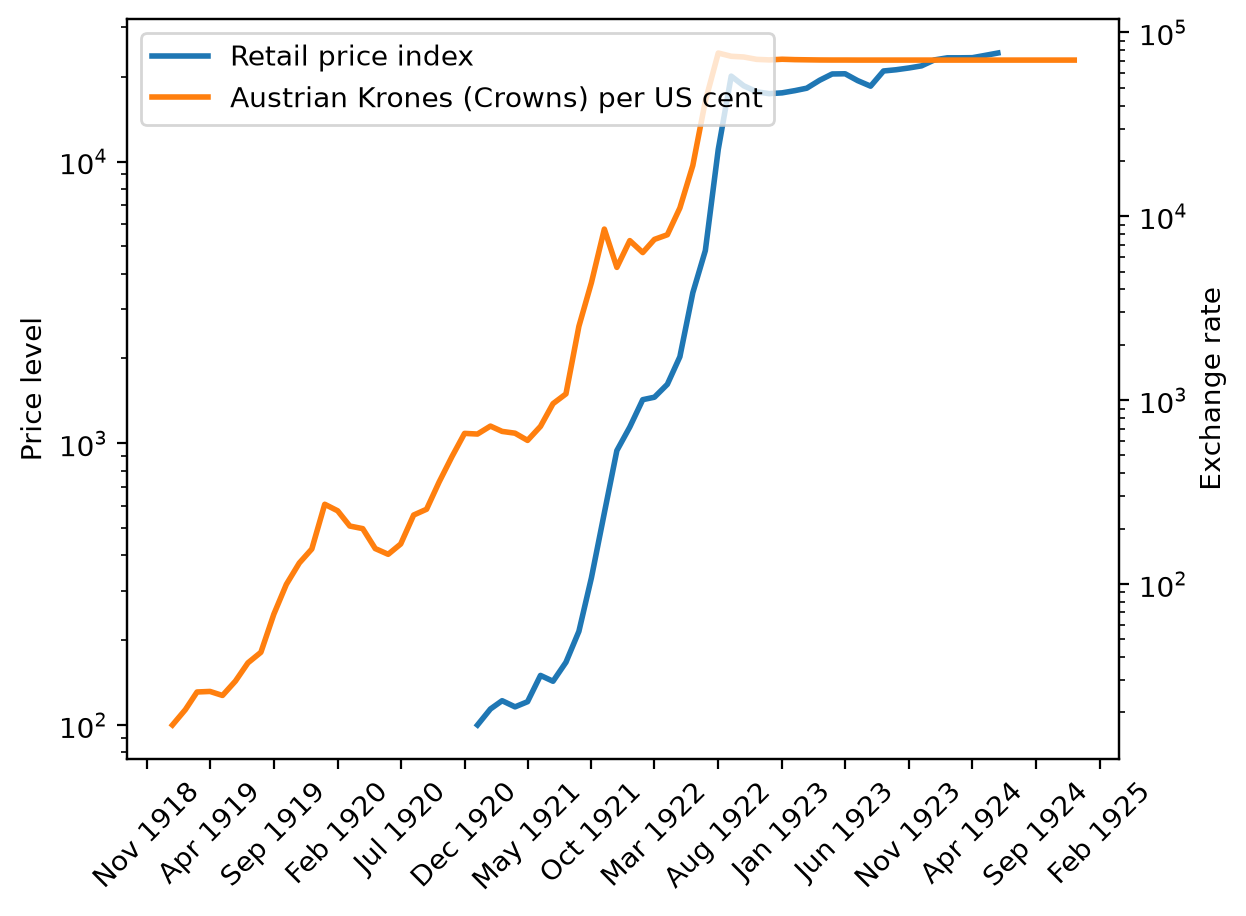

In [ ]:
p_seq = df_aus["Retail price index, 52 commodities"]
e_seq = df_aus["Exchange Rate"]

lab = ["Retail price index", "Austrian Krones (Crowns) per US cent"]

# Create plot
fig, ax = plt.subplots(dpi=200)
_ = pe_plot(p_seq, e_seq, df_aus.index, lab, ax)

plt.show()

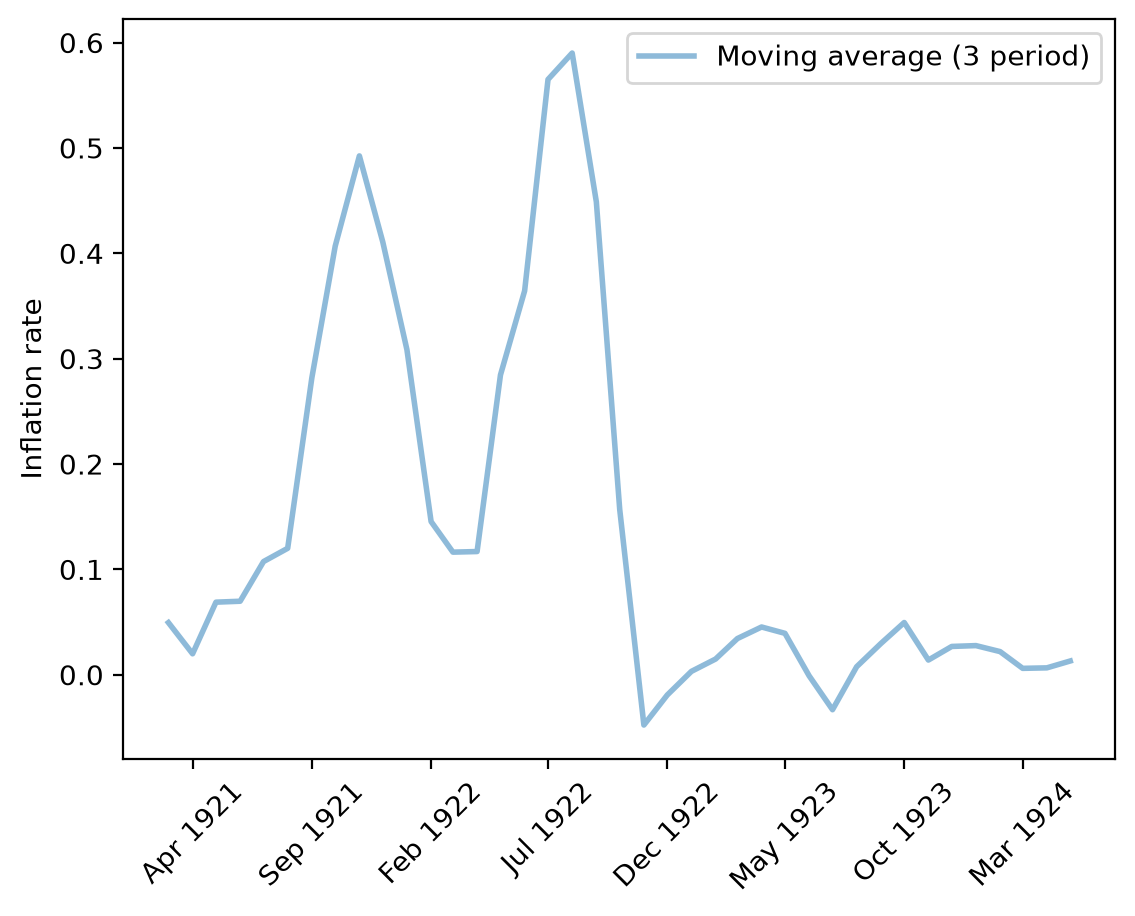

In [12]:
# Plot moving average
fig, ax = plt.subplots(dpi=200)
_ = pr_plot(p_seq, df_aus.index, ax)

plt.show()

Staring at these figures conveys the following impressions to the authors of this lecture at QuantEcon and to the annotator of this notebook.
  * an episode of “hyperinflation” with rapidly rising log price level and very high monthly inflation rates
  * a sudden stop of the hyperinflation as indicated by the abrupt flattening of the log price level and a marked permanent drop in the three-month average of inflation
  * a US dollar exchange rate that shadows the price level.

We’ll see similar patterns in the next three episodes that we’ll study now.

### 4.2.2. Hungary

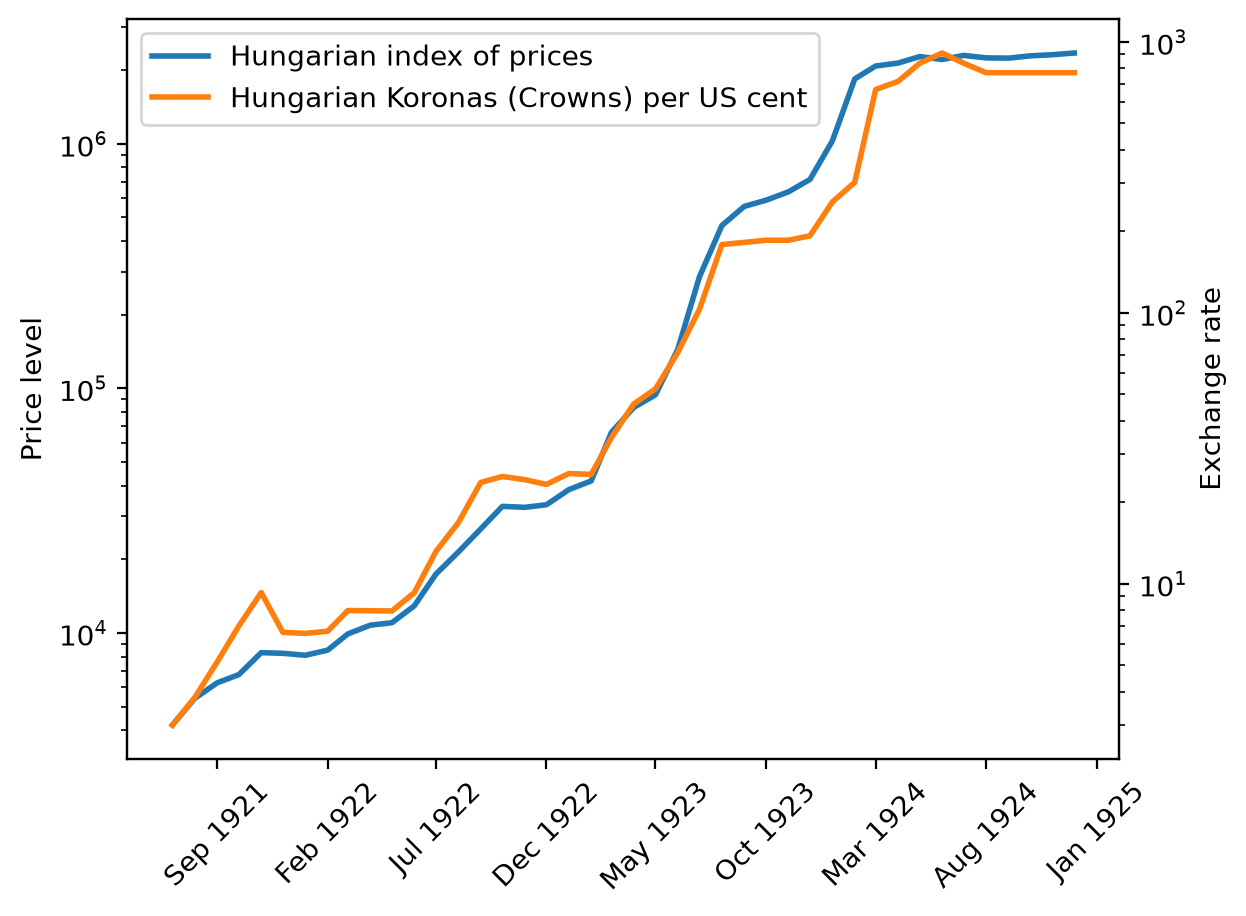

In [ ]:
p_seq = df_hun["Hungarian index of prices"]
e_seq = 1 / df_hun["Cents per crown in New York"]

lab = ["Hungarian index of prices", "Hungarian Koronas (Crowns) per US cent"]

# Create plot
fig, ax = plt.subplots(dpi=200)
_ = pe_plot(p_seq, e_seq, df_hun.index, lab, ax)

plt.show()

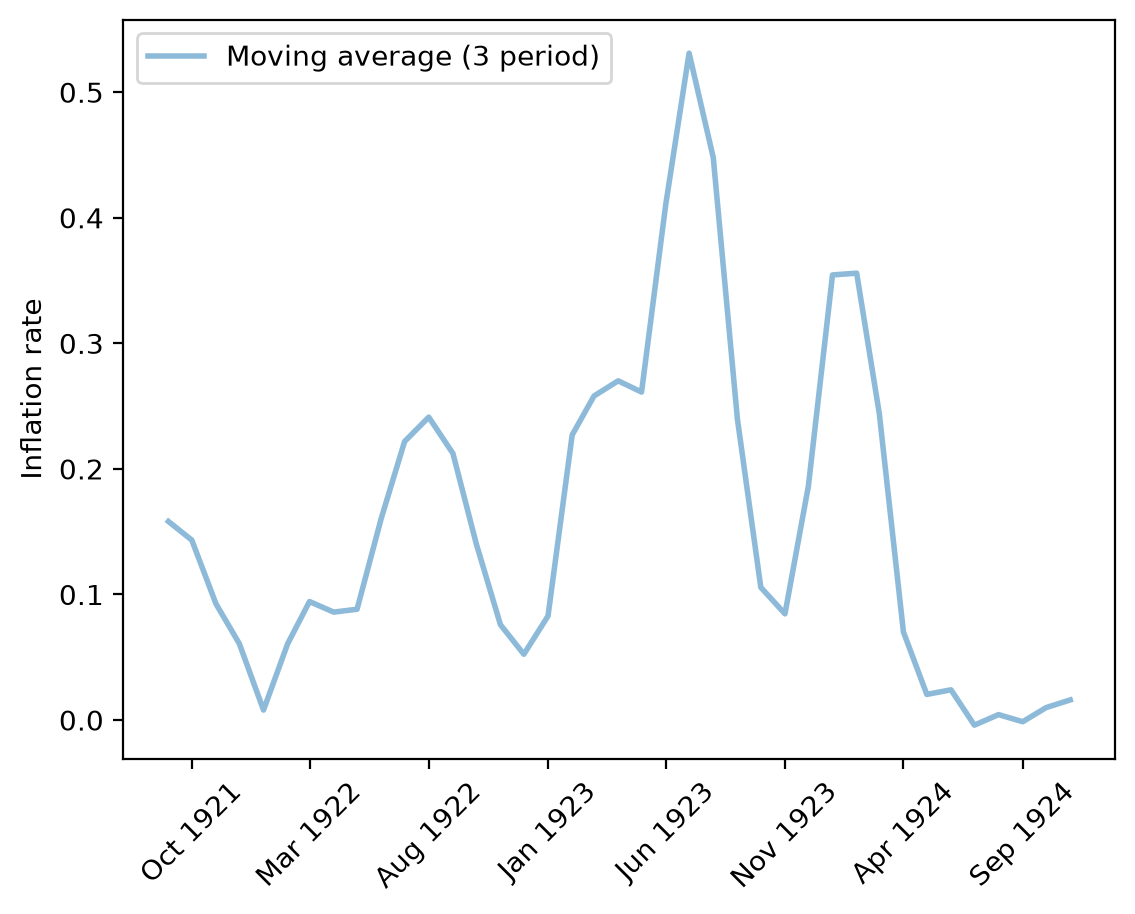

In [14]:
# Plot moving average
fig, ax = plt.subplots(dpi=200)
_ = pr_plot(p_seq, df_hun.index, ax)

plt.show()

### 4.2.3. Poland

In [ ]:
# Splice three price series in different units
p_seq1 = df_pol["Wholesale price index"].copy()
p_seq2 = df_pol["Wholesale Price Index: On paper currency basis"].copy()
p_seq3 = df_pol["Wholesale Price Index: On zloty basis"].copy()

# Non-nan part
mask_1 = p_seq1[~p_seq1.isna()].index[-1]
mask_2 = p_seq2[~p_seq2.isna()].index[-2]

adj_ratio12 = p_seq1[mask_1] / p_seq2[mask_1]
adj_ratio23 = p_seq2[mask_2] / p_seq3[mask_2]

# Glue three series
p_seq = pd.concat(
    [
        p_seq1[:mask_1],
        adj_ratio12 * p_seq2[mask_1:mask_2],
        adj_ratio23 * p_seq3[mask_2:],
    ]
)
p_seq = p_seq[~p_seq.index.duplicated(keep="first")]

# Exchange rate
e_seq = 1 / df_pol["Cents per Polish mark (zloty after May 1924)"]
e_seq[e_seq.index > "05-01-1924"] = np.nan

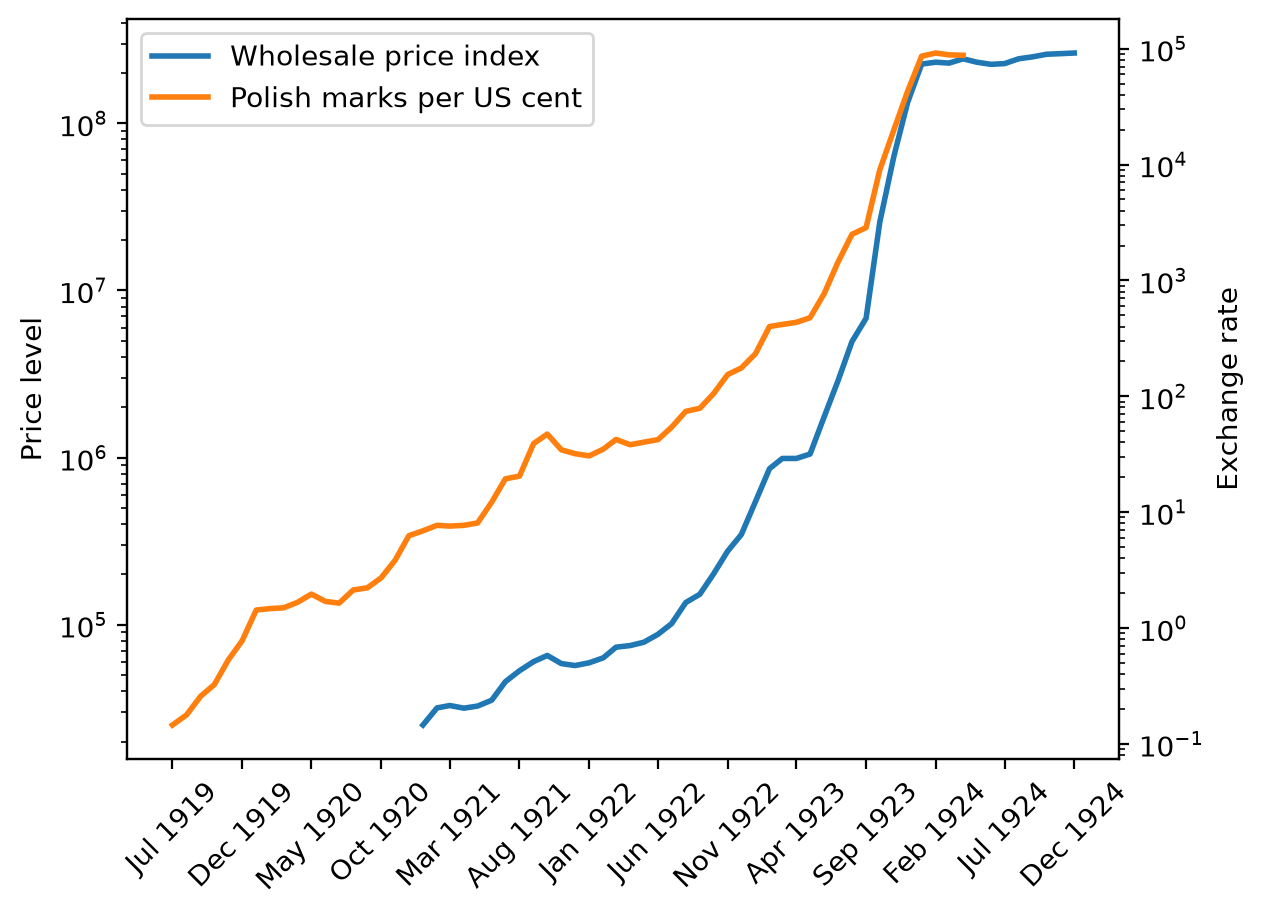

In [ ]:
lab = ["Wholesale price index", "Polish marks per US cent"]

# Create plot
fig, ax = plt.subplots(dpi=200)
ax1 = pe_plot(p_seq, e_seq, df_pol.index, lab, ax)

plt.show()

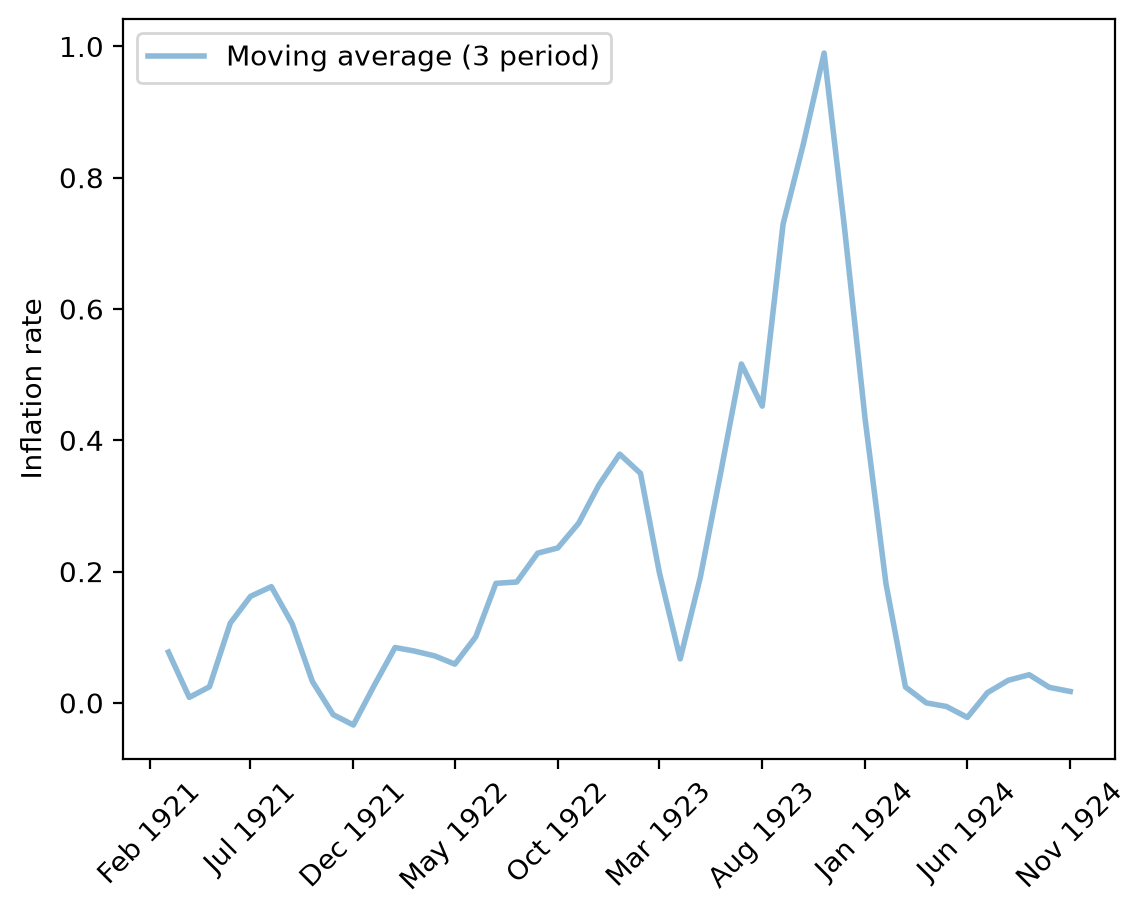

In [17]:
# Plot moving average
fig, ax = plt.subplots(dpi=200)
_ = pr_plot(p_seq, df_pol.index, ax)

plt.show()

### 4.2.4. Germany

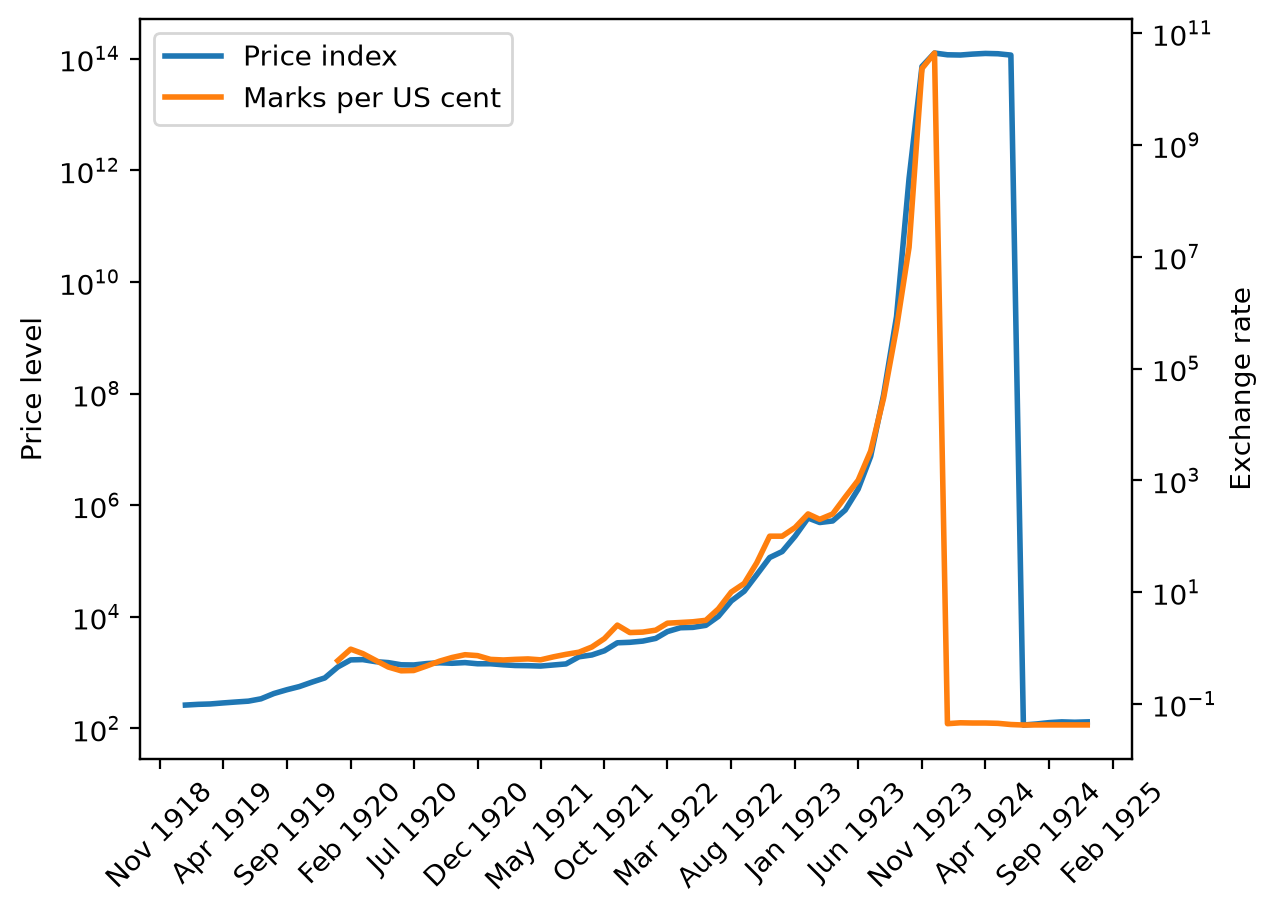

In [ ]:
p_seq = df_deu[
    "Price index (on basis of marks before July 1924,  reichsmarks after)"
].copy()
e_seq = 1 / df_deu["Cents per mark"]

lab = ["Price index", "Marks per US cent"]

# Create plot
fig, ax = plt.subplots(dpi=200)
ax1 = pe_plot(p_seq, e_seq, df_deu.index, lab, ax)

plt.show()

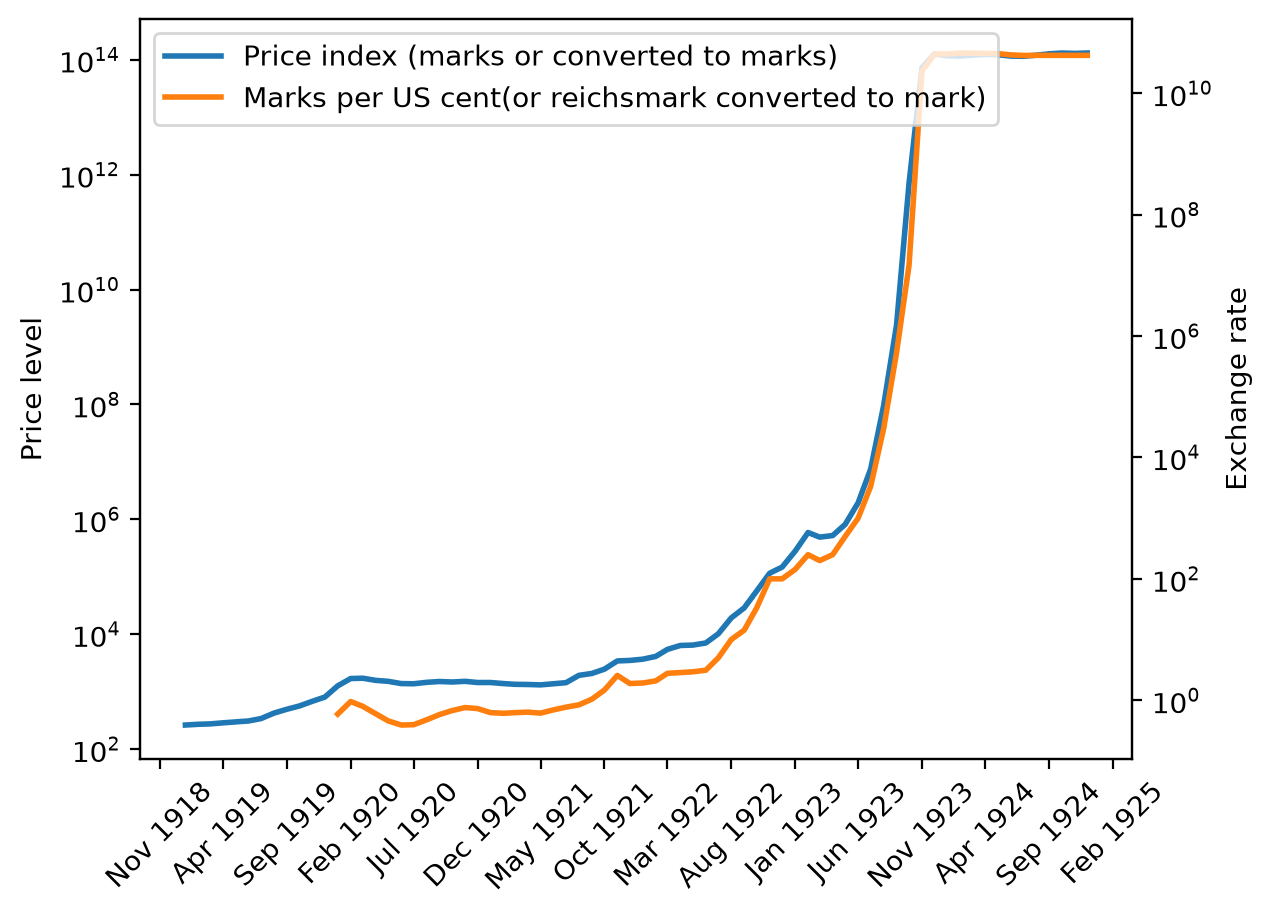

In [ ]:
p_seq = df_deu[
    "Price index (on basis of marks before July 1924,  reichsmarks after)"
].copy()
e_seq = 1 / df_deu["Cents per mark"].copy()

# Adjust the price level/exchange rate after the currency reform
p_seq[p_seq.index > "06-01-1924"] = p_seq[p_seq.index > "06-01-1924"] * 1e12
e_seq[e_seq.index > "12-01-1923"] = e_seq[e_seq.index > "12-01-1923"] * 1e12

lab = [
    "Price index (marks or converted to marks)",
    "Marks per US cent(or reichsmark converted to mark)",
]

# Create plot
fig, ax = plt.subplots(dpi=200)
ax1 = pe_plot(p_seq, e_seq, df_deu.index, lab, ax)

plt.show()

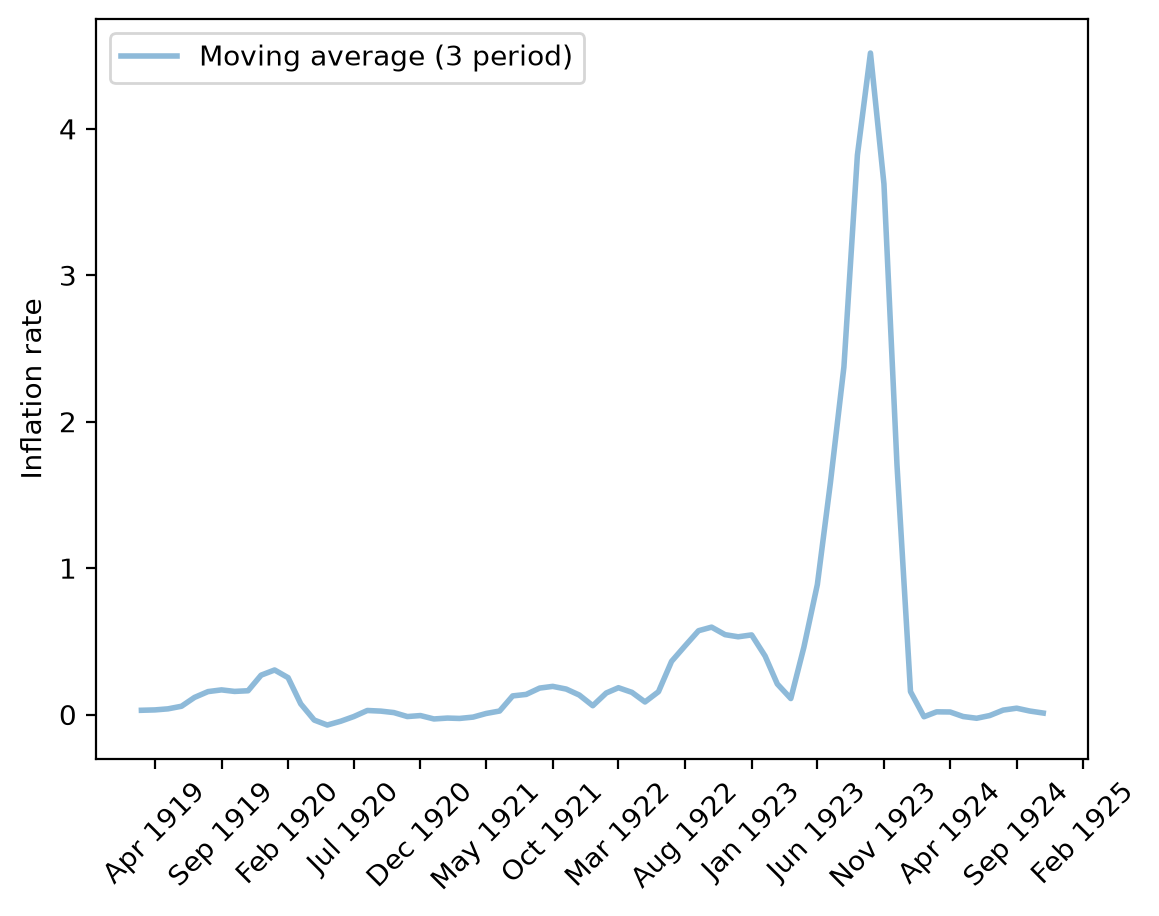

In [20]:
# Plot moving average
fig, ax = plt.subplots(dpi=200)
_ = pr_plot(p_seq, df_deu.index, ax)

plt.show()

# 4.3. Starting and Stopping Big Inflations

It is striking how quickly (log) price levels in Austria, Hungary, Poland, and Germany leveled off after rising so quickly. These “sudden stops” are also revealed by the permanent drops in three-month moving averages of inflation for the four countries plotted above. In addition, the US dollar exchange rates for each of the four countries shadowed their price levels.

> **Note:** This pattern is an instance of a force featured in the purchasing power parity theory of exchange rates.

Each of these big inflations seemed to have “stopped on a dime”. Chapter 3 of [Sargent and Velde, 2002] offers an explanation for this remarkable pattern. In a nutshell, here is the explanation offered there:

After World War I, the United States was on a gold standard. The US government stood ready to convert a dollar into a specified amount of gold on demand. Immediately after World War I, Hungary, Austria, Poland, and Germany were not on the gold standard. Their currencies were “fiat” or “unbacked”, meaning that they were not backed by credible government promises to convert them into gold or silver coins on demand.

The governments printed new paper notes to pay for goods and services. This was done on such a scale that it led to a depreciation of the currencies of spectacular proportions.

> **Note:** Technically the notes were “backed” mainly by treasury bills. But people could not expect that those treasury bills would be paid off by levying taxes, but instead by printing more notes or treasury bills.

In the end, the German mark stabilized at 1 trillion ($10^{12}$) paper marks to the prewar gold mark, the Polish mark at 1.8 million paper marks to the gold zloty, the Austrian crown at 14,400 paper crowns to the prewar Austro-Hungarian crown, and the Hungarian krone at 14,500 paper crowns to the prewar Austro-Hungarian crown.

Chapter 3 of [Sargent and Velde, 2002] described deliberate changes in policy that Hungary, Austria, Poland, and Germany made to end their hyperinflations. Each government stopped printing money to pay for goods and services once again and made its currency convertible to the US dollar or the UK pound. The story told in [Sargent and Velde, 2002] is grounded in a monetarist theory of the price level described in A Monetarist Theory of Price Levels and Monetarist Theory of Price Levels with Adaptive Expectations. Those lectures discuss theories about what owners of those rapidly depreciating currencies were thinking and how their beliefs shaped responses of inflation to government monetary and fiscal policies.

## 4.4 Exercises

### Exercise 4.1.

**Comparing peak monthly inflation rates across the four hyperinflations.**

For each of the four post-World War I hyperinflationary episodes (Austria, Hungary, Poland, Germany), compute the peak monthly log-inflation rate $\Delta \log_{10}\left(p_{t}\right) - \log_{10}\left(p_{t - 1}\right)$ and the calendar month in which it occurred.
  1. Display the four peak log-changes in a bar chart.
  2. Convert each peak log-change to a monthly percentage price rise (i.e., compute
) and print a short table of peak rates and dates.
  3. Which country experienced the most extreme peak monthly inflation?

  > **JACC Note:** I have redefined the result in terms of the base-10 logarithm to allow us to develop direct, order of magnitude intuition.

#### Answer

In [26]:
# Price series directly available from the lecture
p_aus = df_aus["Retail price index, 52 commodities"].dropna()
p_hun = df_hun["Hungarian index of prices"].dropna()
p_deu = df_deu[
    "Price index (on basis of marks before July 1924,  reichsmarks after)"
].dropna()

# Reconstruct the spliced Poland series (following the lecture body)
p_s1 = df_pol["Wholesale price index"].copy()
p_s2 = df_pol["Wholesale Price Index: On paper currency basis"].copy()
p_s3 = df_pol["Wholesale Price Index: On zloty basis"].copy()
m1 = p_s1[~p_s1.isna()].index[-1]
m2 = p_s2[~p_s2.isna()].index[-2]
r12 = p_s1[m1] / p_s2[m1]
r23 = p_s2[m2] / p_s3[m2]
p_pol = pd.concat([p_s1[:m1], r12 * p_s2[m1:m2], r23 * p_s3[m2:]]).dropna()

p_series = {
    "Austria": p_aus,
    "Hungary": p_hun,
    "Poland": p_pol,
    "Germany": p_deu,
}

# Compute peak monthly log-inflation and its date for each country
peak_log = {}
peak_date = {}
for country, p in p_series.items():
    log_infl = pd.Series(np.diff(np.log10(p.values)), index=p.index[1:])
    peak_log[country] = log_infl.max()
    peak_date[country] = log_infl.idxmax()

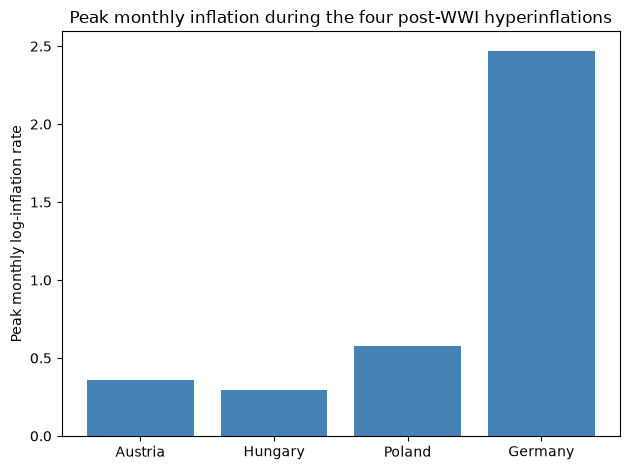

In [27]:
# Part 1: bar chart
fig, ax = plt.subplots()
countries = list(p_series.keys())
ax.bar(countries, [peak_log[c] for c in countries], color="steelblue")
ax.set_ylabel("Peak monthly log-inflation rate")
ax.set_title("Peak monthly inflation during the four post-WWI hyperinflations")
plt.tight_layout()
plt.show()

In [ ]:
# Part 2: print table
print(
    f"{'Country':<10}  {'Peak log-change':>16}  {'Monthly % rise':>14} "
    f" {'Date'}"
)
print("-" * 62)
for c in p_series:
    pct = 100 * (10 ** peak_log[c] - 1)
    print(
        f"{c:<10}  {peak_log[c]:>16.3f}  {pct:>13.1f}%  "
        f"{peak_date[c].strftime('%b %Y')}"
    )

Country      Peak log-change  Monthly % rise  Date
--------------------------------------------------------------
Austria                0.359          128.7%  Aug 1922
Hungary                0.296           97.9%  Jul 1923
Poland                 0.574          275.0%  Oct 1923
Germany                2.472        29524.8%  Oct 1923


**Part 3:** Germany very experienced the most extreme peak monthly inflation, at a rate of ~30,000% in October of 1923.

### Exercise 4.2.

**Gold standard versus fiat money: quantifying long-run price stability.**

The lecture argues that abandoning the gold/silver standard after 1914 unleashed persistent inflation that had been absent over the preceding three centuries.

Using the `df_fig5` dataframe, test this claim quantitatively. For each country in `df_fig5` (UK, US, France, Castile), compute the annualized average log-growth rate of the price level for:
  * The gold-standard era: years 1700 to 1913, and
  * The fiat-money era: years 1914 to 2000.

The annualized rate for a country whose price level rises from $p_{t_{1}}$ in year $t_{1}$ to $p_{t_{2}}$ in year $t_{2}$ is

$$
g = \frac{\log_{10}\left(p_{t_{2}}\right) - \log_{10}\left(p_{t_{1}}\right)}{t_{2} - t_{1}} \, .
$$

> **JACC Note:** I have redefined $g$ in terms of the base-10 logarithm, as this lets up develop direct order of magnitude intuition.

Display your results in a grouped bar chart and comment on what you find.

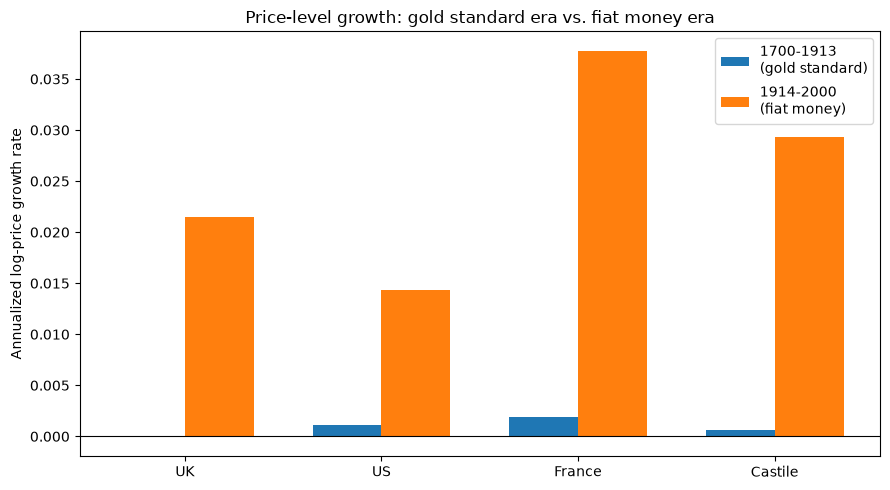

In [ ]:
periods = {
    "1700-1913\n(gold standard)": (1700, 1913),
    "1914-2000\n(fiat money)": (1914, 2000),
}
cols_fig5 = ["UK", "US", "France", "Castile"]
rates = {col: {} for col in cols_fig5}

for col in cols_fig5:
    series = df_fig5[col].dropna()
    for label, (y1, y2) in periods.items():
        sub = series[(series.index >= y1) & (series.index <= y2)]
        if len(sub) >= 2:
            rates[col][label] = (
                np.log10(float(sub.iloc[-1])) - np.log10(float(sub.iloc[0]))
            ) / (sub.index[-1] - sub.index[0])
        else:
            rates[col][label] = np.nan

x = np.arange(len(cols_fig5))
width = 0.35
era_labels = list(periods.keys())

fig, ax = plt.subplots(figsize=(9, 5))
for i, label in enumerate(era_labels):
    vals = [rates[c].get(label, np.nan) for c in cols_fig5]
    ax.bar(x + (i - 0.5) * width, vals, width, label=label)

ax.set_xticks(x)
ax.set_xticklabels(cols_fig5)
ax.set_ylabel("Annualized log-price growth rate")
ax.set_title("Price-level growth: gold standard era vs. fiat money era")
ax.axhline(0, color="black", lw=0.8)
ax.legend()
plt.tight_layout()
plt.show()

This chart seems to largely validate the QuantEcon lecturer's argument that fiat money has led to consistently higher inflation rates vs the preceding gold and silver standard periods. During the gold and silver standard periods, the inflation rate was virtually zero in all four countries. After the implementation of fiat currency, all four countries experienced much higher annual inflation than in the preceding three centuries (though Castile's data does not extend consistently into the 20th century, and thus should be interpretted with caution).

### Exercise 4.3.

**Purchasing power parity during the German hyperinflation.**

The lecture states that the US dollar exchange rate for each country “shadowed” its price level.

This co-movement is a hallmark of purchasing power parity (PPP), which predicts that $\log_{10} e_{t} \approx \log_{10} p_{t} + \text{const.}$, so the real exchange rate $q_{t} = \log_{10} e_{t} - \log_{10} p_{t}$ should be approximately constant.

Examine PPP for the German episode:
  1. Normalize both the log price level and the log exchange rate (marks per US cent) to zero at the first available date, plot both normalized series on the same axes, and assess how closely they track each other.
  2. Compute the Pearson correlation between the two normalized log-level series and print it.
  3. Plot the real exchange rate $q_{t} - \log_{10} e_{t} - \log_{10} p_{t}$ over time and compare the standard deviation of $q_{t}$ with the standard deviation of $\log_{10} p_{t}$ to assess how large the deviations from PPP are relative to the overall price movement.

  > **JACC Note:** I have once again redefined values in terms of the base-10 logarithm.

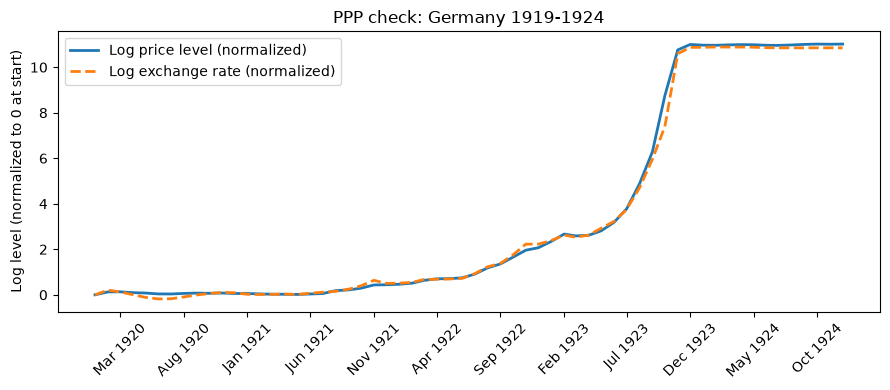

Pearson correlation between log price and log exchange rate: 0.9991


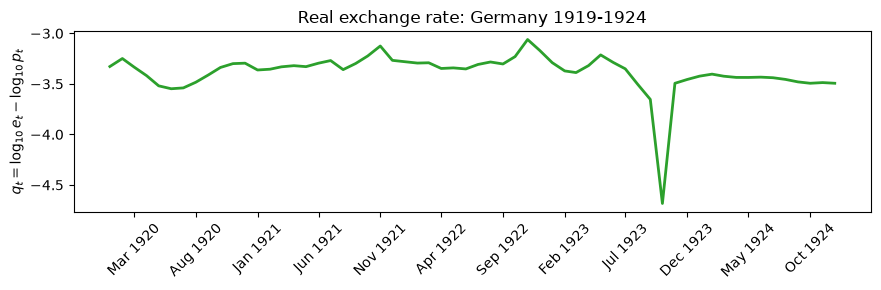

Std dev of log price level (normalized): 4.459
Std dev of real exchange rate q:         0.202


In [ ]:
# Extract Germany price and exchange-rate series and align on common dates
p_ger = df_deu[
    "Price index (on basis of marks before July 1924,  reichsmarks after)"
].dropna()
e_ger = (1 / df_deu["Cents per mark"]).dropna()

# Convert post-reform reichsmark observations back into paper-mark units
p_ger[p_ger.index > "1924-06-01"] = p_ger[p_ger.index > "1924-06-01"] * 1e12
e_ger[e_ger.index > "1923-12-01"] = e_ger[e_ger.index > "1923-12-01"] * 1e12

common = p_ger.index.intersection(e_ger.index)
log_p = np.log10(p_ger[common])
log_e = np.log10(e_ger[common])

# Normalize to zero at the first common date
log_p_n = log_p - log_p.iloc[0]
log_e_n = log_e - log_e.iloc[0]

# Part a: plot normalized log levels
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(common, log_p_n, label="Log price level (normalized)", lw=2)
ax.plot(
    common,
    log_e_n,
    label="Log exchange rate (normalized)",
    lw=2,
    linestyle="--",
)
ax.set_ylabel("Log level (normalized to 0 at start)")
ax.set_title("PPP check: Germany 1919-1924")
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for lbl in ax.get_xticklabels():
    lbl.set_rotation(45)
plt.tight_layout()
plt.show()

# Part b: Pearson correlation
corr = np.corrcoef(log_p_n.values, log_e_n.values)[0, 1]
print(
    f"Pearson correlation between log price and log exchange rate: {corr:.4f}"
)

# Part c: real exchange rate q_t = log e - log p
q = log_e - log_p
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(common, q, lw=2, color="tab:green")
ax.set_ylabel(r"$q_t = \log_{10} e_t - \log_{10} p_t$")
ax.set_title("Real exchange rate: Germany 1919-1924")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for lbl in ax.get_xticklabels():
    lbl.set_rotation(45)
plt.tight_layout()
plt.show()

print(f"Std dev of log price level (normalized): {log_p_n.std():.3f}")
print(f"Std dev of real exchange rate q:         {q.std():.3f}")

We can see for parts 1 and 2 that the normalized price level and exchange rate are nearly identical, and have a high Pearson correlation of nearly 1. We can see that changes in the real exchange rate are relatively small (less than a tenth of a percent) compared to changes in the price level, with a standard deviation of about 0.2 orders of magnitude, vs the price level standard deviation of 4.5.